# Aceleracion por Hardware

In [ ]:
%%sh
nvidia-smi

Fri Oct 16 12:17:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   46C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from itertools import chain
from torch import nn
from torch.nn import functional as F
from torch import optim
from sklearn.datasets import make_moons

plt.style.use("ggplot")

In [ ]:
x = torch.tensor(1.0)

In [ ]:
x

tensor(1.)

In [ ]:
x.shape

torch.Size([])

In [ ]:
x = torch.tensor([1, 2, 3])

In [ ]:
x

tensor([1, 2, 3])

In [ ]:
x.shape

torch.Size([3])

In [ ]:
x = torch.tensor([
    [1, 2],
    [3, 4]
])

In [ ]:
x

tensor([[1, 2],
        [3, 4]])

In [ ]:
x = torch.arange(0, 15)

In [ ]:
x

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14])

In [ ]:
x.reshape((3, 5))

tensor([[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14]])

In [ ]:
torch.arange(0, 27).reshape((3, 3, 3))

tensor([[[ 0,  1,  2],
         [ 3,  4,  5],
         [ 6,  7,  8]],

        [[ 9, 10, 11],
         [12, 13, 14],
         [15, 16, 17]],

        [[18, 19, 20],
         [21, 22, 23],
         [24, 25, 26]]])

In [ ]:
x = torch.randn(size=(1000, 1000))

In [ ]:
x.shape

torch.Size([1000, 1000])

$\mathbf{X}\cdot\mathbf{X}^T$

* CPU

In [ ]:
%%timeit
x @ x.T

20.2 ms ± 6.66 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


* GPU

In [ ]:
x_gpu = x.to("cuda")

In [ ]:
%%timeit
x_gpu @ x_gpu.T

564 µs ± 3.09 µs per loop (mean ± std. dev. of 7 runs, 1000 loops each)


In [ ]:
15.3 / (597 / 1e3)

25.62814070351759

In [ ]:
x_gpu

tensor([[ 0.1934,  0.5665, -1.8724,  ..., -0.9069, -0.2712,  1.2399],
        [-0.3490,  0.3317,  0.6832,  ..., -1.4171,  0.9706, -0.9574],
        [ 1.0900, -0.1596,  0.1771,  ...,  0.1850, -0.6056,  0.9825],
        ...,
        [-0.0795,  0.0540,  0.4406,  ..., -0.8306,  0.8285,  0.1213],
        [-1.8921, -0.5479,  1.9166,  ...,  1.3413, -1.0478, -1.9039],
        [-0.2872, -0.1768,  2.5960,  ...,  0.2922,  0.3850,  1.6536]],
       device='cuda:0')

In [ ]:
x_gpu.dtype

torch.float32

In [ ]:
4 * 10000 ** 2 / 1024 ** 2 + 140

521.4697265625

In [ ]:
!nvidia-smi

Fri Oct 16 12:17:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P0             34W /   70W |     153MiB /  15360MiB |      1%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
y = torch.randn(size=(10000, 10000), device=torch.device("cuda"))

In [ ]:
!nvidia-smi

Fri Oct 16 12:17:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   53C    P0             39W /   70W |     535MiB /  15360MiB |      1%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
def get_ram_usage():
    # Read /proc/meminfo to get system RAM statistics
    with open('/proc/meminfo', 'r') as f:
        lines = f.readlines()

    mem_info = {}
    for line in lines:
        parts = line.split()
        if len(parts) >= 2:
            key = parts[0].rstrip(':')
            val = int(parts[1])
            mem_info[key] = val

    # Calculations in Gigabytes (GB)
    total_ram = mem_info.get('MemTotal', 0) / (1024 ** 2)
    free_ram = mem_info.get('MemFree', 0) / (1024 ** 2)
    buffers = mem_info.get('Buffers', 0) / (1024 ** 2)
    cached = mem_info.get('Cached', 0) / (1024 ** 2)

    # Used RAM = Total - Free - Buffers - Cached (standard Linux calculation)
    used_ram = total_ram - free_ram - buffers - cached

    print(f"Total RAM: {total_ram:.2f} GB")
    print(f"Used RAM:  {used_ram:.2f} GB")
    print(f"Free RAM:  {free_ram:.2f} GB")

get_ram_usage()

Total RAM: 12.67 GB
Used RAM:  1.71 GB
Free RAM:  6.68 GB


# Diferenciacion Automatica

\begin{equation}
y = 5 x^2 - 3x + 2\\
\frac{dy}{dx} = 10x - 3
\end{equation}

In [ ]:
def forward(x: float) -> float:
    return 5 * x ** 2 - 3 * x + 2

In [ ]:
def backward(x: float) -> float:
    return 10 * x - 3

In [ ]:
forward(5)

112

In [ ]:
backward(5)

47

In [ ]:
x = torch.tensor(5.0, requires_grad=True, device=torch.device("cuda"))

In [ ]:
y = forward(x)

In [ ]:
y

tensor(112., device='cuda:0', grad_fn=<AddBackward0>)

In [ ]:
y.backward()

In [ ]:
x.grad

tensor(47., device='cuda:0')

# Grafo Computacional

In [ ]:
x = torch.tensor([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
    ], device=torch.device("cuda"))

In [ ]:
x_ones = torch.concat([x, torch.ones(size=(x.shape[0], 1), device=torch.device("cuda"))], dim=1)

In [ ]:
x_ones

tensor([[0., 0., 1.],
        [0., 1., 1.],
        [1., 0., 1.],
        [1., 1., 1.]], device='cuda:0')

In [ ]:
x_ones.dtype

torch.float32

In [ ]:
y = torch.tensor([0, 0, 0, 1], device=torch.device("cuda"), dtype=torch.float32).reshape(-1, 1)

In [ ]:
y.dtype

torch.float32

In [ ]:
def sigmoid(x: torch.Tensor) -> torch.Tensor:
    return 1 / (1 + torch.exp(-x))

In [ ]:
def forward(x: torch.Tensor, w: torch.Tensor) -> torch.Tensor:
    return sigmoid(x @ w)

In [ ]:
w = torch.randn(size=(3, 1), requires_grad=True, device=torch.device("cuda"))

In [ ]:
x.dtype

torch.float32

In [ ]:
def train(x: torch.Tensor, y: torch.Tensor, w: torch.Tensor, lr: float, n_iters: int) -> torch.Tensor:
    for _ in range(n_iters):
        y_pred = forward(x, w)
        loss = F.binary_cross_entropy(y_pred, y)
        print(f"Loss: {loss.item()}")
        loss.backward()
        with torch.no_grad():
            w -= lr * w.grad

In [ ]:
train(x_ones, y, w, 0.1, 100)

Loss: 1.2655367851257324
Loss: 1.2347995042800903
Loss: 1.1763951778411865
Loss: 1.0965313911437988
Loss: 1.0044317245483398
Loss: 0.9115545153617859
Loss: 0.8297249674797058
Loss: 0.7684096097946167
Loss: 0.7323346138000488
Loss: 0.720811665058136
Loss: 0.7289804816246033
Loss: 0.7499603033065796
Loss: 0.776739776134491
Loss: 0.8032682538032532
Loss: 0.8248217105865479
Loss: 0.8379461765289307
Loss: 0.8402392268180847
Loss: 0.8301209211349487
Loss: 0.8066586256027222
Loss: 0.7694682478904724
Loss: 0.7187033295631409
Loss: 0.6551501750946045
Loss: 0.5804610848426819
Loss: 0.4975573420524597
Loss: 0.41116392612457275
Loss: 0.328172892332077
Loss: 0.2570568919181824
Loss: 0.20553897321224213
Loss: 0.17742735147476196
Loss: 0.17145845293998718
Loss: 0.18311810493469238
Loss: 0.20709878206253052
Loss: 0.23852118849754333
Loss: 0.2731228172779083
Loss: 0.3071657121181488
Loss: 0.3374154567718506
Loss: 0.36121195554733276
Loss: 0.37656453251838684
Loss: 0.3822218179702759
Loss: 0.37770450115

In [ ]:
y_pred = forward(x_ones, w)

In [ ]:
y_pred

tensor([[6.5389e-14],
        [1.2995e-06],
        [2.5206e-06],
        [9.8043e-01]], device='cuda:0', grad_fn=<MulBackward0>)

In [ ]:
y

tensor([[0.],
        [0.],
        [0.],
        [1.]], device='cuda:0')

# Red Multicapa

In [ ]:
X, y = make_moons(n_samples=1000, noise=0.1, random_state=0)

[Text(0.5, 0, '$x_1$'), Text(0, 0.5, '$x_2$')]

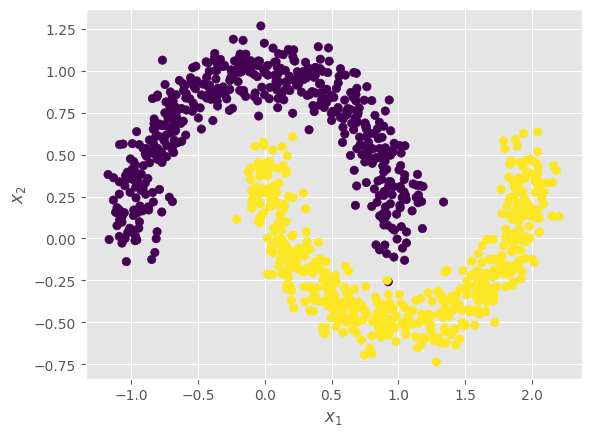

In [ ]:
fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], c=y)
ax.set(xlabel="$x_1$", ylabel="$x_2$")

linear > sigmoid > linear > sigmoid

In [ ]:
x = [[1, 2], [3, 4], [5, 6]]
list(chain(*x))

[1, 2, 3, 4, 5, 6]

In [ ]:
list(chain(*[(1, 2) for i in range(10)]))

[1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2, 1, 2]

In [ ]:
class BinaryPerceptron(nn.Module):
    def __init__(self, neurons_per_layer: list[int]) -> None:
        super().__init__()
        self.layers = nn.ModuleList(chain(*[
            (nn.Linear(neurons_per_layer[i], neurons_per_layer[i + 1]), nn.Sigmoid())
            for i in range(len(neurons_per_layer) -1)]
        ))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # h_1 = self.layers[0](x)
        # h_2 = self.layers[1](h_1)
        # h_3 = self.layers[2](h_2)
        for layer in self.layers:
            x = layer(x)
        return x

In [ ]:
class BinaryPerceptron(nn.Module):
    def __init__(self, neurons_per_layer: list[int]) -> None:
        super().__init__()
        self.layers = nn.ModuleList(
            nn.Linear(neurons_per_layer[i], neurons_per_layer[i + 1])
            for i in range(len(neurons_per_layer) -1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for layer in self.layers:
            x = F.sigmoid(layer(x))
        return x

In [ ]:
class SigmoidLayer(nn.Module):
    def __init__(self, in_features: int, out_features: int) -> None:
        super().__init__()
        self.layer = nn.Linear(in_features, out_features)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.sigmoid(self.layer(x))


class BinaryPerceptron(nn.Module):
    def __init__(self, neurons_per_layer: list[int]) -> None:
        super().__init__()
        self.layers = nn.ModuleList(
            SigmoidLayer(neurons_per_layer[i], neurons_per_layer[i + 1])
            for i in range(len(neurons_per_layer) -1)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        for layer in self.layers:
            x = layer(x)
        return x

In [ ]:
model = BinaryPerceptron(neurons_per_layer=[2, 16, 1])

In [ ]:
for i, layer in enumerate(model.layers):
    print(f"Layer {i}")
    print(f"w: {layer.layer.weight.numel()}")
    print(f"b: {layer.layer.bias.numel()}")

Layer 0
w: 32
b: 16
Layer 1
w: 16
b: 1


In [ ]:
x_test = torch.randn(size=(10, 2))

In [ ]:
X_torch = torch.from_numpy(X).float()
X_torch_gpu = X_torch.to("cuda")
y_torch = torch.from_numpy(y).float().reshape(-1, 1)
y_torch_gpu = y_torch.to("cuda")

model_gpu = model.to("cuda")

In [ ]:
model(X_torch)

tensor([[0.3784],
        [0.3710],
        [0.3950],
        [0.3849],
        [0.3733],
        [0.3772],
        [0.3823],
        [0.3964],
        [0.3971],
        [0.3701],
        [0.3883],
        [0.3847],
        [0.3670],
        [0.3942],
        [0.3810],
        [0.3828],
        [0.3732],
        [0.3908],
        [0.3800],
        [0.3855],
        [0.3822],
        [0.3888],
        [0.3964],
        [0.3984],
        [0.3698],
        [0.3693],
        [0.3787],
        [0.3868],
        [0.3706],
        [0.3786],
        [0.3683],
        [0.3721],
        [0.3785],
        [0.3668],
        [0.3942],
        [0.3699],
        [0.3764],
        [0.3961],
        [0.3737],
        [0.3973],
        [0.3981],
        [0.3799],
        [0.3768],
        [0.3738],
        [0.4012],
        [0.3696],
        [0.3665],
        [0.3908],
        [0.3980],
        [0.3777],
        [0.3959],
        [0.3992],
        [0.3961],
        [0.3914],
        [0.3707],
        [0

In [ ]:
model_gpu(X_torch_gpu)

tensor([[0.3784],
        [0.3710],
        [0.3950],
        [0.3849],
        [0.3733],
        [0.3772],
        [0.3823],
        [0.3964],
        [0.3971],
        [0.3701],
        [0.3883],
        [0.3847],
        [0.3670],
        [0.3942],
        [0.3810],
        [0.3828],
        [0.3732],
        [0.3908],
        [0.3800],
        [0.3855],
        [0.3822],
        [0.3888],
        [0.3964],
        [0.3984],
        [0.3698],
        [0.3693],
        [0.3787],
        [0.3868],
        [0.3706],
        [0.3786],
        [0.3683],
        [0.3721],
        [0.3785],
        [0.3668],
        [0.3942],
        [0.3699],
        [0.3764],
        [0.3961],
        [0.3737],
        [0.3973],
        [0.3981],
        [0.3799],
        [0.3768],
        [0.3738],
        [0.4012],
        [0.3696],
        [0.3665],
        [0.3908],
        [0.3980],
        [0.3777],
        [0.3959],
        [0.3992],
        [0.3961],
        [0.3914],
        [0.3707],
        [0

In [ ]:
def train(
        model: nn.Module,
        x: torch.Tensor,
        y: torch.Tensor,
        optimizer: torch.optim.Optimizer,
        n_iters: int
        ) -> None:
    for _ in range(n_iters):
        y_pred = model(x)
        loss = F.binary_cross_entropy(y_pred, y)
        print(f"Loss: {loss.item()}")
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

In [ ]:
model_gpu = BinaryPerceptron(neurons_per_layer=[2, 128, 64, 1]).to("cuda")
optimizer = optim.Adam(model_gpu.parameters(), lr=1e-3)
train(model_gpu, X_torch_gpu, y_torch_gpu, optimizer, 1000)

Loss: 0.6920610666275024
Loss: 0.6885283589363098
Loss: 0.6852250099182129
Loss: 0.681950032711029
Loss: 0.6786304712295532
Loss: 0.6752579212188721
Loss: 0.671840488910675
Loss: 0.6683816909790039
Loss: 0.6648772954940796
Loss: 0.661317765712738
Loss: 0.6576932072639465
Loss: 0.6539946794509888
Loss: 0.6502156257629395
Loss: 0.646351158618927
Loss: 0.6423983573913574
Loss: 0.6383549571037292
Loss: 0.6342193484306335
Loss: 0.6299899220466614
Loss: 0.6256656646728516
Loss: 0.6212460994720459
Loss: 0.6167311072349548
Loss: 0.6121214628219604
Loss: 0.6074188351631165
Loss: 0.602625846862793
Loss: 0.5977452993392944
Loss: 0.5927812457084656
Loss: 0.5877376794815063
Loss: 0.5826193690299988
Loss: 0.5774314403533936
Loss: 0.5721790790557861
Loss: 0.5668684244155884
Loss: 0.5615053772926331
Loss: 0.5560968518257141
Loss: 0.5506496429443359
Loss: 0.5451708436012268
Loss: 0.539668083190918
Loss: 0.534148633480072
Loss: 0.5286202430725098
Loss: 0.5230906009674072
Loss: 0.5175672173500061
Loss: 0

In [ ]:
y_pred = model_gpu(X_torch_gpu).detach().to("cpu").numpy()
y_pred.shape

(1000, 1)

In [ ]:
np.linspace(-1, 1, 10)

array([-1.        , -0.77777778, -0.55555556, -0.33333333, -0.11111111,
        0.11111111,  0.33333333,  0.55555556,  0.77777778,  1.        ])

[Text(0.5, 0, '$x_1$'), Text(0, 0.5, '$x_2$')]

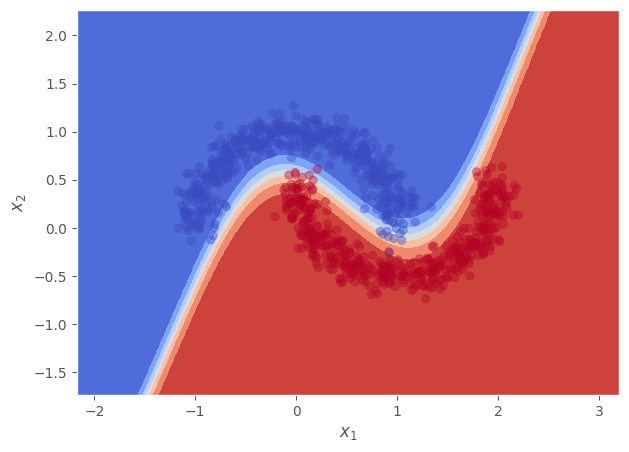

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
x1 = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)
x2 = np.linspace(X[:, 1].min() - 1, X[:, 1].max() + 1, 100)
X1_grid, X2_grid = np.meshgrid(x1, x2)
X_grid = np.c_[X1_grid.ravel(), X2_grid.ravel()]
y_pred = model_gpu(torch.from_numpy(X_grid).float().to("cuda")).detach().to("cpu").numpy()
y_pred = y_pred.reshape(X1_grid.shape)
ax.contourf(X1_grid, X2_grid, y_pred, cmap="coolwarm")
ax.scatter(X[:, 0], X[:, 1], c=y.flatten(), alpha=0.4, cmap="coolwarm")
ax.set(xlabel="$x_1$", ylabel="$x_2$")